# Phase 2 – Basismodelle: Was bestimmt den Ertrag? (F0, F1)

Darstellung der **vorhandenen** Ergebnisdateien (`results/2026-10-16_phase2`, `round1–3`, `within_field`).
Es wird nichts neu trainiert und es werden keine österreichischen Daten geöffnet.
Validierung überall LOFYO (Feldgruppe × Jahr ausgelassen), Stichtag 1.9. falls nicht anders angegeben, 95-%-KI per Cluster-Bootstrap über Standort-Jahre.
ρ = Spearman-Rangkorrelation zwischen vorhergesagtem und gemessenem relativem Ertrag (RY).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

# Resolve repo root whether run from notebooks/ or the root
ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
RES, FIG = ROOT / "results", ROOT / "reports" / "figures"
P2 = RES / "2026-10-16_phase2"
WF = RES / "2026-10-16_within_field"

CUTS = ["06-01", "06-15", "07-01", "07-15", "08-01", "08-15", "09-01"]
CUT_LABEL = {c: f"{int(c[3:])}.{int(c[:2])}." for c in CUTS}
MODELS = ["B1", "M-S", "M-W", "M-B", "M-B+", "M-WB", "M-SW", "M-SB", "M-alle"]

pd.options.display.float_format = "{:.2f}".format
pd.options.display.max_rows = 100
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

m = pd.read_csv(P2 / "metrics.csv")
main = m[m["variant"] == "main"].copy()
crit = json.loads((P2 / "criteria_main.json").read_text(encoding="utf-8"))
print("Läufe (metrics.csv):", len(m), "| davon Variante main:", len(main))

Läufe (metrics.csv): 350 | davon Variante main: 238


## 1. Modell × Stichtag: ρ [95-%-KI]

Zeilen: Modell und Lernverfahren (Ridge / LightGBM). Spalten: Stichtag, an dem die Merkmale enden.
Modellgruppen: **S** = Satellit, **W** = Wetter, **B** = Boden; B1 = Baseline mit Trend. HLS-Basis: 123 Feld-Jahre / 11 Standort-Jahre, S2-Basis: 89 / 8.
Gepoolt über alle Feld-Jahre; die KI sind breit und schließen fast überall 0 ein.

In [2]:
def pivot_rho(basis):
    d = main[main["basis"] == basis].copy()
    d["cell"] = d.apply(lambda r: f"{r.rho:.2f} [{r.rho_lo:.2f}; {r.rho_hi:.2f}]", axis=1)
    p = d.pivot_table(index=["model", "kind"], columns="cutoff", values="cell", aggfunc="first")
    p = p.reindex(MODELS, level="model").dropna(how="all")
    p = p[CUTS].rename(columns=CUT_LABEL)
    return p, int(d["n"].iloc[0]), int(d["clusters"].iloc[0])

for basis in ["HLS", "S2"]:
    p, n, k = pivot_rho(basis)
    print(f"Basis {basis}: n = {n} Feld-Jahre, {k} Standort-Jahre")
    display(p)

Basis HLS: n = 123 Feld-Jahre, 11 Standort-Jahre


cutoff                       1.6.                 15.6.                 1.7.  \
model  kind                                                                    
B1     ridge   0.29 [-0.05; 0.49]   -0.12 [-0.30; 0.14]  -0.07 [-0.25; 0.18]   
M-S    lgbm    0.23 [-0.14; 0.60]   -0.22 [-0.42; 0.24]  -0.46 [-0.60; 0.00]   
       ridge   0.33 [-0.05; 0.58]   -0.34 [-0.52; 0.16]  -0.43 [-0.58; 0.05]   
M-W    lgbm    0.02 [-0.32; 0.33]  -0.41 [-0.51; -0.02]   0.25 [-0.25; 0.54]   
       ridge   0.12 [-0.30; 0.38]   -0.22 [-0.56; 0.09]   0.30 [-0.12; 0.52]   
M-B    lgbm    0.01 [-0.18; 0.25]    0.01 [-0.18; 0.25]   0.01 [-0.18; 0.25]   
       ridge   0.03 [-0.17; 0.31]    0.03 [-0.17; 0.31]   0.03 [-0.17; 0.31]   
M-B+   lgbm   -0.00 [-0.19; 0.25]   -0.00 [-0.19; 0.25]  -0.00 [-0.19; 0.25]   
       ridge   0.05 [-0.16; 0.31]    0.05 [-0.16; 0.31]   0.05 [-0.16; 0.31]   
M-WB   lgbm    0.14 [-0.18; 0.30]   -0.22 [-0.36; 0.04]   0.20 [-0.22; 0.46]   
       ridge   0.21 [-0.12; 0.41]   -0.20 [-0.49; 0.14]   0.27 [-0.06; 0.40]   
M-SW   lgbm     0.31 [0.06; 0.47]   -0.27 [-0.43; 0.03]   0.16 [-0.23; 0.44]   
       ridge   0.45 [-0.01; 0.63]   -0.26 [-0.50; 0.11]  -0.00 [-0.26; 0.27]   
M-SB   lgbm    0.16 [-0.10; 0.43]   -0.15 [-0.32; 0.25]  -0.25 [-0.47; 0.14]   
       ridge    0.32 [0.02; 0.57]   -0.11 [-0.28; 0.25]  -0.29 [-0.42; 0.05]   
M-alle lgbm     0.31 [0.05; 0.48]   -0.11 [-0.30; 0.07]   0.07 [-0.23; 0.27]   
       ridge    0.45 [0.00; 0.60]   -0.06 [-0.26; 0.23]  -0.07 [-0.30; 0.17]   

cutoff                       15.7.                 1.8.                 15.8.  \
model  kind                                                                     
B1     ridge   -0.19 [-0.40; 0.11]   0.05 [-0.11; 0.32]   -0.01 [-0.15; 0.25]   
M-S    lgbm   -0.43 [-0.64; -0.02]  -0.31 [-0.50; 0.16]   -0.42 [-0.60; 0.04]   
       ridge   -0.30 [-0.53; 0.11]   0.04 [-0.30; 0.34]   -0.17 [-0.44; 0.30]   
M-W    lgbm     0.01 [-0.40; 0.41]   0.17 [-0.24; 0.50]   -0.07 [-0.40; 0.27]   
       ridge   -0.04 [-0.42; 0.30]  -0.06 [-0.39; 0.46]   -0.35 [-0.50; 0.13]   
M-B    lgbm     0.01 [-0.18; 0.25]   0.01 [-0.18; 0.25]    0.01 [-0.18; 0.25]   
       ridge    0.03 [-0.17; 0.31]   0.03 [-0.17; 0.31]    0.03 [-0.17; 0.31]   
M-B+   lgbm    -0.00 [-0.19; 0.25]  -0.00 [-0.19; 0.25]   -0.00 [-0.19; 0.25]   
       ridge    0.05 [-0.16; 0.31]   0.05 [-0.16; 0.31]    0.05 [-0.16; 0.31]   
M-WB   lgbm    -0.04 [-0.32; 0.20]   0.10 [-0.25; 0.44]   -0.08 [-0.33; 0.23]   
       ridge    0.03 [-0.22; 0.26]   0.01 [-0.40; 0.50]   -0.26 [-0.51; 0.17]   
M-SW   lgbm    -0.34 [-0.57; 0.06]  -0.35 [-0.49; 0.17]  -0.42 [-0.56; -0.00]   
       ridge   -0.20 [-0.40; 0.14]  -0.25 [-0.45; 0.31]   -0.18 [-0.42; 0.21]   
M-SB   lgbm   -0.36 [-0.56; -0.00]  -0.23 [-0.49; 0.24]   -0.36 [-0.55; 0.09]   
       ridge   -0.26 [-0.49; 0.14]   0.05 [-0.28; 0.37]   -0.23 [-0.45; 0.21]   
M-alle lgbm    -0.34 [-0.55; 0.03]  -0.33 [-0.54; 0.17]   -0.37 [-0.56; 0.06]   
       ridge   -0.23 [-0.43; 0.10]  -0.08 [-0.33; 0.42]   -0.27 [-0.52; 0.19]   

cutoff                       1.9.  
model  kind                        
B1     ridge  -0.17 [-0.51; 0.25]  
M-S    lgbm   -0.30 [-0.50; 0.17]  
       ridge  -0.16 [-0.45; 0.25]  
M-W    lgbm   -0.15 [-0.30; 0.15]  
       ridge  -0.22 [-0.47; 0.19]  
M-B    lgbm    0.01 [-0.18; 0.25]  
       ridge   0.03 [-0.17; 0.31]  
M-B+   lgbm   -0.00 [-0.19; 0.25]  
       ridge   0.05 [-0.16; 0.31]  
M-WB   lgbm   -0.07 [-0.26; 0.22]  
       ridge  -0.02 [-0.36; 0.34]  
M-SW   lgbm   -0.42 [-0.60; 0.02]  
       ridge  -0.28 [-0.51; 0.19]  
M-SB   lgbm   -0.28 [-0.55; 0.22]  
       ridge  -0.08 [-0.34; 0.24]  
M-alle lgbm   -0.37 [-0.60; 0.10]  
       ridge  -0.14 [-0.45; 0.28]

Basis S2: n = 89 Feld-Jahre, 8 Standort-Jahre


cutoff                        1.6.                 15.6.  \
model  kind                                                
B1     ridge  -0.37 [-0.52; -0.15]  -0.37 [-0.48; -0.02]   
M-S    lgbm     0.27 [-0.02; 0.44]   -0.16 [-0.32; 0.20]   
       ridge    0.23 [-0.12; 0.40]    0.25 [-0.13; 0.49]   
M-W    lgbm    -0.08 [-0.57; 0.23]  -0.37 [-0.59; -0.04]   
       ridge    0.10 [-0.44; 0.36]   -0.18 [-0.62; 0.11]   
M-B    lgbm    -0.03 [-0.34; 0.35]   -0.03 [-0.34; 0.35]   
       ridge   -0.01 [-0.36; 0.38]   -0.01 [-0.36; 0.38]   
M-B+   lgbm    -0.04 [-0.35; 0.36]   -0.04 [-0.35; 0.36]   
       ridge   -0.00 [-0.34; 0.31]   -0.00 [-0.34; 0.31]   
M-WB   lgbm     0.08 [-0.43; 0.34]   -0.34 [-0.47; 0.01]   
       ridge    0.23 [-0.27; 0.45]   -0.15 [-0.54; 0.23]   
M-SW   lgbm     0.25 [-0.14; 0.49]    0.00 [-0.19; 0.51]   
       ridge    0.08 [-0.36; 0.26]   -0.08 [-0.36; 0.13]   
M-SB   lgbm     0.12 [-0.03; 0.28]   -0.06 [-0.25; 0.32]   
       ridge    0.25 [-0.20; 0.42]    0.10 [-0.19; 0.39]   
M-alle lgbm     0.11 [-0.22; 0.30]   -0.00 [-0.27; 0.38]   
       ridge    0.11 [-0.34; 0.32]    0.04 [-0.51; 0.34]   

cutoff                        1.7.                 15.7.                 1.8.  \
model  kind                                                                     
B1     ridge  -0.42 [-0.51; -0.16]  -0.33 [-0.51; -0.08]  -0.12 [-0.43; 0.45]   
M-S    lgbm    -0.18 [-0.34; 0.15]    0.02 [-0.23; 0.39]   0.25 [-0.01; 0.49]   
       ridge   -0.01 [-0.30; 0.14]    0.10 [-0.07; 0.41]   0.01 [-0.32; 0.29]   
M-W    lgbm    -0.01 [-0.34; 0.23]   -0.30 [-0.45; 0.15]   0.03 [-0.26; 0.55]   
       ridge    0.00 [-0.40; 0.16]  -0.36 [-0.49; -0.05]   0.18 [-0.26; 0.62]   
M-B    lgbm    -0.03 [-0.34; 0.35]   -0.03 [-0.34; 0.35]  -0.03 [-0.34; 0.35]   
       ridge   -0.01 [-0.36; 0.38]   -0.01 [-0.36; 0.38]  -0.01 [-0.36; 0.38]   
M-B+   lgbm    -0.04 [-0.35; 0.36]   -0.04 [-0.35; 0.36]  -0.04 [-0.35; 0.36]   
       ridge   -0.00 [-0.34; 0.31]   -0.00 [-0.34; 0.31]  -0.00 [-0.34; 0.31]   
M-WB   lgbm    -0.06 [-0.35; 0.25]   -0.23 [-0.38; 0.14]  -0.05 [-0.29; 0.46]   
       ridge    0.10 [-0.34; 0.29]   -0.19 [-0.44; 0.15]   0.23 [-0.25; 0.66]   
M-SW   lgbm    -0.15 [-0.38; 0.02]   -0.04 [-0.26; 0.35]   0.23 [-0.08; 0.50]   
       ridge    0.19 [-0.27; 0.37]    0.18 [-0.17; 0.41]   0.19 [-0.11; 0.53]   
M-SB   lgbm    -0.14 [-0.29; 0.30]   -0.05 [-0.26; 0.55]   0.15 [-0.21; 0.44]   
       ridge   -0.04 [-0.34; 0.11]    0.07 [-0.01; 0.36]   0.15 [-0.14; 0.37]   
M-alle lgbm    -0.13 [-0.33; 0.14]   -0.10 [-0.29; 0.33]   0.16 [-0.21; 0.50]   
       ridge    0.08 [-0.31; 0.29]   -0.00 [-0.33; 0.21]   0.23 [-0.03; 0.39]   

cutoff                      15.8.                 1.9.  
model  kind                                             
B1     ridge  -0.15 [-0.45; 0.34]  -0.18 [-0.52; 0.18]  
M-S    lgbm    0.40 [-0.13; 0.67]   0.21 [-0.29; 0.42]  
       ridge   0.21 [-0.42; 0.53]  -0.04 [-0.29; 0.37]  
M-W    lgbm    0.14 [-0.37; 0.43]  -0.18 [-0.47; 0.12]  
       ridge  -0.18 [-0.38; 0.21]   0.04 [-0.13; 0.22]  
M-B    lgbm   -0.03 [-0.34; 0.35]  -0.03 [-0.34; 0.35]  
       ridge  -0.01 [-0.36; 0.38]  -0.01 [-0.36; 0.38]  
M-B+   lgbm   -0.04 [-0.35; 0.36]  -0.04 [-0.35; 0.36]  
       ridge  -0.00 [-0.34; 0.31]  -0.00 [-0.34; 0.31]  
M-WB   lgbm    0.08 [-0.24; 0.35]  -0.11 [-0.31; 0.13]  
       ridge  -0.07 [-0.41; 0.26]   0.20 [-0.24; 0.46]  
M-SW   lgbm    0.41 [-0.16; 0.66]   0.19 [-0.28; 0.37]  
       ridge   0.21 [-0.28; 0.50]   0.04 [-0.18; 0.27]  
M-SB   lgbm    0.40 [-0.18; 0.66]   0.19 [-0.33; 0.38]  
       ridge   0.23 [-0.31; 0.55]  -0.13 [-0.36; 0.27]  
M-alle lgbm    0.40 [-0.18; 0.64]   0.20 [-0.36; 0.39]  
       ridge   0.24 [-0.22; 0.52]    0.23 [0.05; 0.43]

## 2. Frühwarnkurve: ρ gegen den Stichtag

Ausgewählte Modelle (Ridge, außer wo angegeben) mit KI-Band. Eine brauchbare Frühwarnung müsste mit wachsendem Stichtag klar über 0 steigen; hier bleibt die Kurve um 0.

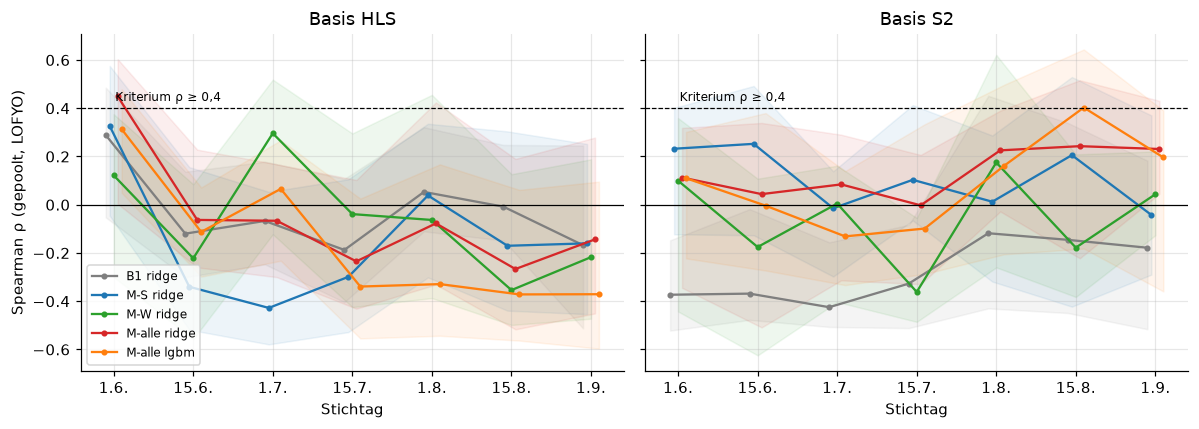

In [3]:
SEL = [("B1", "ridge", "#7f7f7f"), ("M-S", "ridge", "#1f77b4"), ("M-W", "ridge", "#2ca02c"),
       ("M-alle", "ridge", "#d62728"), ("M-alle", "lgbm", "#ff7f0e")]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
x = np.arange(len(CUTS))
for ax, basis in zip(axes, ["HLS", "S2"]):
    for i, (mod, kind, col) in enumerate(SEL):
        d = main[(main.basis == basis) & (main.model == mod) & (main.kind == kind)].set_index("cutoff").reindex(CUTS)
        xs = x + (i - 2) * 0.05
        ax.plot(xs, d.rho, "-o", ms=3, color=col, label=f"{mod} {kind}")
        ax.fill_between(xs, d.rho_lo, d.rho_hi, color=col, alpha=0.08)
    ax.axhline(0, color="k", lw=0.8)
    ax.axhline(0.4, color="k", lw=0.8, ls="--")
    ax.text(0.02, 0.43, "Kriterium ρ ≥ 0,4", fontsize=8)
    ax.set_xticks(x, [CUT_LABEL[c] for c in CUTS])
    ax.set_title(f"Basis {basis}")
    ax.set_xlabel("Stichtag")
axes[0].set_ylabel("Spearman ρ (gepoolt, LOFYO)")
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

## 3. Ablation am 1.9.: M-alle gegen M-WB, M-SB, M-SW

Jedes Vergleichsmodell lässt genau eine Gruppe weg: M-WB ohne Satellit, M-SB ohne Wetter, M-SW ohne Boden.
Δ = M-alle − Vergleichsmodell (Differenz der Punktschätzer; keine gepaarten KI vorhanden).
Δρ > 0: die weggelassene Gruppe hilft bei der Rangfolge. ΔRMSE > 0: M-alle ist im Fehler **schlechter**.

,Basis,Verfahren,Vergleich,ρ alle,ρ Vergl.,Δρ,RMSE alle,RMSE Vergl.,ΔRMSE
0,HLS,ridge,M-WB (ohne Satellit),-0.14,-0.02,-0.13,0.34,0.28,0.06
1,HLS,ridge,M-SB (ohne Wetter),-0.14,-0.08,-0.06,0.34,0.35,-0.01
2,HLS,ridge,M-SW (ohne Boden),-0.14,-0.28,0.14,0.34,0.36,-0.02
3,HLS,lgbm,M-WB (ohne Satellit),-0.37,-0.07,-0.30,0.34,0.30,0.04
4,HLS,lgbm,M-SB (ohne Wetter),-0.37,-0.28,-0.09,0.34,0.34,0.01
5,HLS,lgbm,M-SW (ohne Boden),-0.37,-0.42,0.05,0.34,0.35,-0.01
6,S2,ridge,M-WB (ohne Satellit),0.23,0.20,0.03,0.55,0.28,0.27
7,S2,ridge,M-SB (ohne Wetter),0.23,-0.13,0.36,0.55,0.68,-0.13
8,S2,ridge,M-SW (ohne Boden),0.23,0.04,0.19,0.55,0.53,0.01
9,S2,lgbm,M-WB (ohne Satellit),0.20,-0.11,0.31,0.32,0.31,0.01


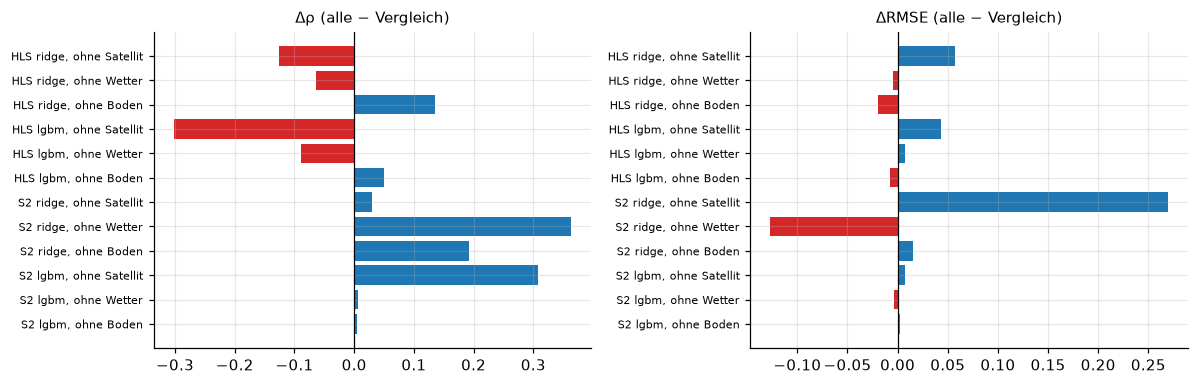

In [4]:
rows = []
for basis in ["HLS", "S2"]:
    for kind in ["ridge", "lgbm"]:
        d = main[(main.cutoff == "09-01") & (main.basis == basis) & (main.kind == kind)].set_index("model")
        for other, lost in [("M-WB", "ohne Satellit"), ("M-SB", "ohne Wetter"), ("M-SW", "ohne Boden")]:
            a, b = d.loc["M-alle"], d.loc[other]
            rows.append({"Basis": basis, "Verfahren": kind, "Vergleich": f"{other} ({lost})",
                         "ρ alle": a.rho, "ρ Vergl.": b.rho, "Δρ": a.rho - b.rho,
                         "RMSE alle": a.rmse, "RMSE Vergl.": b.rmse, "ΔRMSE": a.rmse - b.rmse})
abl = pd.DataFrame(rows)
display(abl)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
lab = abl["Basis"] + " " + abl["Verfahren"] + ", " + abl["Vergleich"].str.extract(r"\((.*)\)")[0]
for ax, col, ttl in zip(axes, ["Δρ", "ΔRMSE"], ["Δρ (alle − Vergleich)", "ΔRMSE (alle − Vergleich)"]):
    ax.barh(range(len(abl)), abl[col], color=np.where(abl[col] >= 0, "#1f77b4", "#d62728"))
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(range(len(abl)), lab, fontsize=7)
    ax.set_title(ttl, fontsize=10)
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 4. Kontrollen (`criteria_main.json`)

Gewähltes Modell: M-S Ridge S2 (nach vorab festgelegter Regel). LOFYO lässt Feldgruppe und Jahr aus, **LOYO** nur das Jahr, **LOFO** nur das Feld (Jahr gesehen).
**LODO** = Leave-One-Dataset-Out (Training auf einem Standort, Test auf dem anderen).
Label-Shuffle: Ziel zufällig permutiert, ρ muss auf Zufallsniveau fallen.

,Kontrolle,ρ,KI unten,KI oben,n
0,LOFYO (gewähltes Modell),-0.04,-0.29,0.37,89
1,LOYO (Jahr ausgelassen),0.00,-0.32,0.48,89
2,"LOFO (Feld ausgelassen, Jahr gesehen)",0.65,0.31,0.75,89
3,LODO KBS→BARC,0.42,-0.06,0.92,17
4,LODO BARC→KBS,-0.19,-0.36,0.32,72
5,Label-Shuffle,-0.00,-0.22,0.35,89


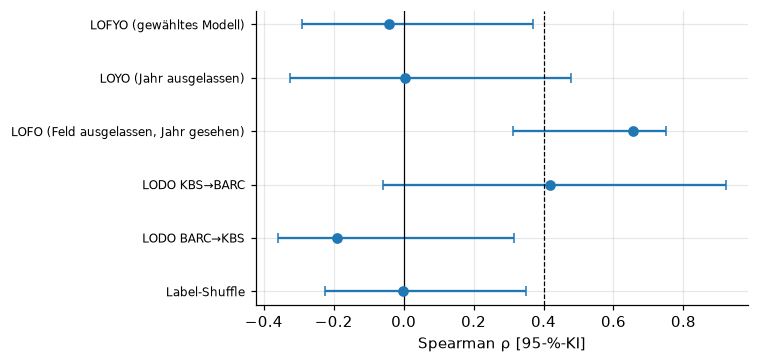

,Kontrolle,Wert,Hinweis
0,Adversarial AUC KBS vs. BARC,1.00,"gdd, n_obs_hls, ndvi_hls_last"
1,Conformal 80 %: Abdeckung,0.79,halbe Breite 0.78 RY
2,Conformal 90 %: Abdeckung,0.89,halbe Breite 0.97 RY


SHAP-Anteile nach Gruppe (M-alle LightGBM, 1.9.; nur Erklärung im Trainingsdatensatz): {'S': 0.22, 'W': 0.13, 'B': 0.14}


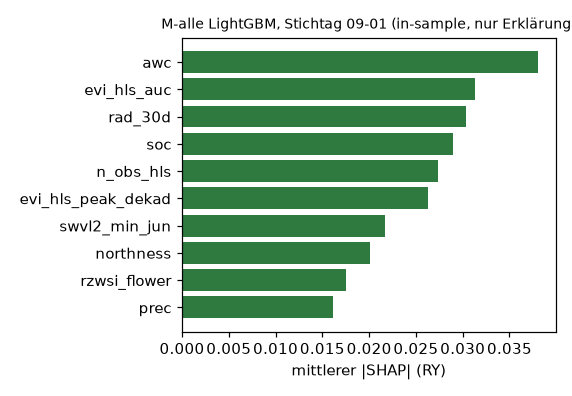

In [5]:
sel, cr = crit["selected"], crit["criteria"]
ctl = [
    ("LOFYO (gewähltes Modell)", sel["rho"], sel["rho_lo"], sel["rho_hi"], sel["n"]),
    ("LOYO (Jahr ausgelassen)", crit["LOYO"]["rho"], crit["LOYO"]["rho_lo"], crit["LOYO"]["rho_hi"], crit["LOYO"]["n"]),
    ("LOFO (Feld ausgelassen, Jahr gesehen)", crit["LOFO"]["rho"], crit["LOFO"]["rho_lo"], crit["LOFO"]["rho_hi"], crit["LOFO"]["n"]),
]
for key, name in [("KBS->BARC", "LODO KBS→BARC"), ("BARC->KBS", "LODO BARC→KBS")]:
    c = cr["3_lodo_both_directions_rho_gt_0"][key]
    ctl.append((name, c["rho"], c["lo"], c["hi"], c["n"]))
c = cr["4_label_shuffle_baseline"]
ctl.append(("Label-Shuffle", c["rho"], c["lo"], c["hi"], sel["n"]))
ctl = pd.DataFrame(ctl, columns=["Kontrolle", "ρ", "KI unten", "KI oben", "n"])
display(ctl)

fig, ax = plt.subplots(figsize=(7, 3.4))
y = np.arange(len(ctl))
ax.errorbar(ctl["ρ"], y, xerr=[ctl["ρ"] - ctl["KI unten"], ctl["KI oben"] - ctl["ρ"]],
            fmt="o", color="#1f77b4", capsize=3)
ax.axvline(0, color="k", lw=0.8)
ax.axvline(0.4, color="k", lw=0.8, ls="--")
ax.set_yticks(y, ctl["Kontrolle"], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Spearman ρ [95-%-KI]")
plt.tight_layout()
plt.show()

adv, c80, c90 = crit["adversarial_KBS_vs_BARC"], crit["conformal_80"], crit["conformal_90"]
display(pd.DataFrame([
    {"Kontrolle": "Adversarial AUC KBS vs. BARC", "Wert": adv["auc"], "Hinweis": ", ".join(adv["top_features"][:3])},
    {"Kontrolle": "Conformal 80 %: Abdeckung", "Wert": c80["coverage"], "Hinweis": f"halbe Breite {c80['median_halfwidth']:.2f} RY"},
    {"Kontrolle": "Conformal 90 %: Abdeckung", "Wert": c90["coverage"], "Hinweis": f"halbe Breite {c90['median_halfwidth']:.2f} RY"},
]))
print("SHAP-Anteile nach Gruppe (M-alle LightGBM, 1.9.; nur Erklärung im Trainingsdatensatz):",
      {k: round(v, 2) for k, v in crit["shap_M-alle_lgbm_0901"]["by_group"].items()})
display(Image(FIG / "phase2_shap_main.png", width=520))

**Lesart:** Das Label-Shuffle-Ergebnis liegt bei ρ ≈ 0 (keine Leakage-Spur). LOFO ≫ LOFYO/LOYO: Das Modell überträgt auf neue Felder in bekannten Jahren, nicht auf ungesehene Jahre.
Adversarial AUC = 1,0: Die Standorte sind in den Merkmalen vollständig trennbar, die wichtigsten Einzelmerkmale sind daher eher Standort-Kennungen als Ursachen.
Conformal-Intervalle sind formal kalibriert, aber sehr breit.

## 5. Verbesserungsrunden 1–3 (vorab festgelegt, höchstens drei)

Tabelle am 1.9. (LOFYO) für alle Modelle der Runde; Phase 2 (M-S Ridge S2) zur Referenz. Das je Stufe gewählte Modell (zweite Tabelle) folgt der vorab festgelegten Auswahlregel (DECISIONS), nicht dem höchsten ρ. Danach die vier Kriterien „stark genug“ (PLAN Phase 4).

In [6]:
rounds = {r: pd.read_csv(RES / f"2026-10-16_round{r}" / "metrics.csv") for r in (1, 2, 3)}
refrow = main[(main.cutoff == "09-01") & (main.model == "M-S") & (main.kind == "ridge") & (main.basis == "S2")]
parts = [refrow.assign(Runde="Phase 2")]
for r, d in rounds.items():
    parts.append(d[d.cutoff == "09-01"].assign(Runde=f"Runde {r}"))
t = pd.concat(parts, ignore_index=True)
t["ρ [KI]"] = t.apply(lambda r: f"{r.rho:.2f} [{r.rho_lo:.2f}; {r.rho_hi:.2f}]", axis=1)
t["ΔRMSE vs B0 [KI]"] = t.apply(lambda r: f"{r.d_rmse_b0:.2f} [{r.d_rmse_b0_lo:.2f}; {r.d_rmse_b0_hi:.2f}]", axis=1)
display(t[["Runde", "model", "kind", "basis", "n", "ρ [KI]", "median_within_year_rho", "rmse", "ΔRMSE vs B0 [KI]"]]
        .rename(columns={"model": "Modell", "kind": "Verfahren", "basis": "Basis",
                         "median_within_year_rho": "Median-ρ im Jahr", "rmse": "RMSE"}))

,Runde,Modell,Verfahren,Basis,n,ρ [KI],Median-ρ im Jahr,RMSE,ΔRMSE vs B0 [KI]
0,Phase 2,M-S,ridge,S2,89,-0.04 [-0.29; 0.37],0.40,0.61,0.33 [0.11; 0.46]
1,Runde 1,M-Srel,lgbm,HLS,123,-0.24 [-0.52; 0.33],0.09,0.32,0.05 [-0.02; 0.10]
2,Runde 1,M-Srel,lgbm,S2,89,0.47 [0.19; 0.66],0.17,0.27,-0.02 [-0.06; 0.03]
3,Runde 1,M-Srel,ridge,HLS,123,-0.06 [-0.43; 0.38],0.08,0.32,0.05 [-0.01; 0.12]
4,Runde 1,M-Srel,ridge,S2,89,0.37 [-0.01; 0.70],0.50,0.49,0.20 [-0.07; 0.43]
5,Runde 1,M-alle-rel,lgbm,HLS,123,-0.23 [-0.52; 0.27],0.12,0.33,0.06 [0.00; 0.10]
6,Runde 1,M-alle-rel,lgbm,S2,89,0.41 [0.05; 0.68],0.10,0.27,-0.02 [-0.07; 0.03]
7,Runde 1,M-alle-rel,ridge,HLS,123,-0.11 [-0.52; 0.45],-0.04,0.36,0.10 [-0.00; 0.20]
8,Runde 1,M-alle-rel,ridge,S2,89,0.55 [0.26; 0.70],0.35,0.50,0.21 [-0.02; 0.36]
9,Runde 2,M-Srel-einfach,lgbm,HLS,123,-0.18 [-0.48; 0.29],0.16,0.32,0.06 [-0.01; 0.12]


,Stufe,Modell,ρ 1.9. [KI],1 schlägt B0/B1,"2 ρ ≥ 0,4",3 LODO (K→B / B→K),4 Shuffle,stark genug
0,Phase 2,M-S ridge S2,-0.04 [-0.29; 0.37],nein,nein,0.42 / -0.19 nein,ja,nein
1,Runde 1,M-Srel ridge S2,0.37 [-0.01; 0.70],nein,nein,0.47 / 0.40 ja,ja,nein
2,Runde 2,M-Srel-einfach ridge S2,-0.01 [-0.21; 0.59],nein,nein,-0.21 / 0.18 nein,ja,nein
3,Runde 3,M-alle-rel ridge S2,0.37 [-0.02; 0.68],nein,nein,0.77 / 0.53 ja,ja,nein


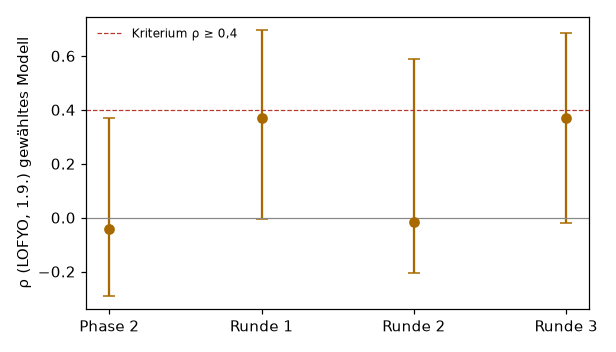

In [7]:
def mark(ok):
    return "ja" if ok else "nein"

def crit_row(label, c):
    s, k = c["selected"], c["criteria"]
    k1, k2, k3, k4 = [k[x] for x in k if x[0] in "1234"][:4]
    lodo = f"{k3['KBS->BARC']['rho']:.2f} / {k3['BARC->KBS']['rho']:.2f}"
    return {"Stufe": label, "Modell": f"{s['model']} {s['kind']} {s['basis']}",
            "ρ 1.9. [KI]": f"{s['rho']:.2f} [{s['rho_lo']:.2f}; {s['rho_hi']:.2f}]",
            "1 schlägt B0/B1": mark(k1["passed"]), "2 ρ ≥ 0,4": mark(k2["passed"]),
            f"3 LODO (K→B / B→K)": f"{lodo} {mark(k3['passed'])}", "4 Shuffle": mark(k4["passed"]),
            "stark genug": mark(c["strong_enough"])}

cr_rows = [crit_row("Phase 2", crit)]
for r in (1, 2, 3):
    cr_rows.append(crit_row(f"Runde {r}", json.loads((RES / f"2026-10-16_round{r}" / "criteria.json").read_text(encoding="utf-8"))))
display(pd.DataFrame(cr_rows))
display(Image(FIG / "phase4_rounds.png", width=520))

Relative Merkmale verbessern die Rangfolge (ρ ≈ 0,37, beide LODO-Richtungen > 0 in Runde 1 und 3), aber **keine Stufe** erfüllt Kriterium 1 (RMSE besser als „normales Jahr“, RY = 1) und 2 (ρ ≥ 0,4).
Hauptgrund: nur 8 unabhängige Standort-Jahre in der S2-Basis. Weitere Runden sind nach der Vorab-Festlegung nicht erlaubt.

## 6. Innerhalb der Felder (BARC, 41 Feld-Jahre, S2)

Relativer Pixel-Ertrag = Pixel / Mittel des Feld-Jahres; Problemzone = relativer Ertrag < 0,85. Fenster: w1 = 15.6.–15.7., w2 = 16.7.–15.8., w3 = 16.8.–15.9.
KI über Feld-Jahre (Bootstrap). Quelle: `results/2026-10-16_within_field/metrics.json`.

In [8]:
wf = json.loads((WF / "metrics.json").read_text(encoding="utf-8"))
WIN = {"w1": "15.6.–15.7.", "w2": "16.7.–15.8.", "w3": "16.8.–15.9."}
print("Zusammenfassung:", {k: (round(v, 2) if isinstance(v, float) else v) for k, v in wf["summary"].items()})

rows = []
for w in WIN:
    for idx in ["ndvi", "ndre"]:
        a, b = wf["index_vs_rel_yield"][f"{idx}_{w}"], wf["index_vs_rel_yield_interior"][f"{idx}_{w}"]
        rows.append({"Fenster": WIN[w], "Index": idx.upper(), "n Feld-Jahre": a["n_fy"],
                     "Median-ρ [KI]": f"{a['rho_median']:.2f} [{a['rho_ci'][0]:.2f}; {a['rho_ci'][1]:.2f}]",
                     "Anteil ρ>0": a["frac_rho_pos"],
                     "ρ ohne äußere 20 m": b["rho_median"],
                     "PR-AUC Problemzone": a["pr_auc_median"], "Prävalenz": a["prevalence_median"]})
display(pd.DataFrame(rows))

Zusammenfassung: {'n_fy_requested': 41, 'n_fy_with_cache': 41, 'n_pixels_inside': 23912, 'n_points_total': 32671, 'n_fields': 27, 'pixels_per_fy_median': 532.0, 'prevalence_problem_median': 0.27, 'n_fy_with_problem_zone': 41, 'rel_cv_median': 0.26}


,Fenster,Index,n Feld-Jahre,Median-ρ [KI],Anteil ρ>0,ρ ohne äußere 20 m,PR-AUC Problemzone,Prävalenz
0,15.6.–15.7.,NDVI,41,0.45 [0.34; 0.53],0.90,0.53,0.53,0.27
1,15.6.–15.7.,NDRE,41,0.49 [0.37; 0.57],0.90,0.55,0.56,0.27
2,16.7.–15.8.,NDVI,41,0.68 [0.54; 0.72],1.00,0.71,0.66,0.27
3,16.7.–15.8.,NDRE,41,0.68 [0.62; 0.73],1.00,0.72,0.63,0.27
4,16.8.–15.9.,NDVI,41,0.35 [0.27; 0.52],0.83,0.44,0.51,0.27
5,16.8.–15.9.,NDRE,41,0.40 [0.34; 0.55],0.90,0.52,0.50,0.27


In [9]:
# Pixel model: LightGBM / Ridge, features terrain / satellite / both; cutoffs w1..w3 = 15.7., 15.8., 15.9.
STICH = {"w1": "15.7.", "w2": "15.8.", "w3": "15.9."}
FEAT = {"terrain": "nur Gelände", "satellite": "nur Satellit", "both": "beides"}
rows = []
for key, v in wf["models"].items():
    if key.startswith("shuffle"):
        continue  # label-shuffle controls are printed below
    w, feat, kind, split = key.split("|")
    rows.append({"Stichtag": STICH[w], "Merkmale": FEAT[feat], "Verfahren": kind, "Split": split.upper(),
                 "cell": f"{v['rho_median']:.2f} [{v['rho_ci'][0]:.2f}; {v['rho_ci'][1]:.2f}]", "R² gepoolt": v["r2_pooled"]})
pm = pd.DataFrame(rows)
pv = pm.pivot_table(index=["Stichtag", "Merkmale", "Verfahren"], columns="Split", values="cell", aggfunc="first")
pv = pv[["LOFYO", "LOYO", "LOFO"]].join(
    pm[pm.Split == "LOFO"].set_index(["Stichtag", "Merkmale", "Verfahren"])["R² gepoolt"].rename("R² (LOFO)"))
display(pv.reindex(["nur Gelände", "nur Satellit", "beides"], level="Merkmale"))
sh = wf["models"]["shuffle_w2|satellite|lgbm|lofyo"]
print(f"Label-Shuffle-Kontrolle (Satellit, LightGBM, LOFYO, 15.8.): Median-ρ {sh['rho_median']:.2f} "
      f"[{sh['rho_ci'][0]:.2f}; {sh['rho_ci'][1]:.2f}]")

ab = [{"Fenster/Stichtag": STICH[k.split("|")[0]], "Verfahren": k.split("|")[1], "Split": k.split("|")[2].upper(),
       "Vergleich": k.split("|")[3], "Δ Median-ρ": v["median_delta_rho"],
       "KI": f"[{v['ci'][0]:.2f}; {v['ci'][1]:.2f}]"} for k, v in wf["ablation_deltas"].items() if k.startswith("w2|")]
print("Ablation (gepaarte Differenz je Feld-Jahr, Stichtag 15.8.):")
display(pd.DataFrame(ab))

LOFYO               LOYO  \
Stichtag Merkmale     Verfahren                                         
15.7.    nur Gelände  lgbm       0.29 [0.17; 0.36]  0.28 [0.16; 0.34]   
                      ridge      0.25 [0.19; 0.32]  0.25 [0.17; 0.32]   
         nur Satellit lgbm       0.48 [0.36; 0.57]  0.48 [0.39; 0.57]   
                      ridge      0.48 [0.32; 0.57]  0.48 [0.36; 0.57]   
         beides       lgbm       0.49 [0.42; 0.59]  0.48 [0.39; 0.58]   
                      ridge      0.48 [0.40; 0.58]  0.48 [0.37; 0.58]   
15.8.    nur Gelände  lgbm       0.29 [0.17; 0.36]  0.28 [0.16; 0.34]   
                      ridge      0.25 [0.19; 0.32]  0.25 [0.17; 0.32]   
         nur Satellit lgbm       0.70 [0.65; 0.74]  0.70 [0.64; 0.74]   
                      ridge      0.70 [0.57; 0.74]  0.70 [0.56; 0.74]   
         beides       lgbm       0.71 [0.62; 0.76]  0.70 [0.62; 0.74]   
                      ridge      0.69 [0.58; 0.75]  0.69 [0.58; 0.74]   
15.9.    nur Gelände  lgbm       0.29 [0.17; 0.36]  0.28 [0.16; 0.34]   
                      ridge      0.25 [0.19; 0.32]  0.25 [0.17; 0.32]   
         nur Satellit lgbm       0.70 [0.61; 0.75]  0.68 [0.65; 0.76]   
                      ridge      0.69 [0.59; 0.74]  0.69 [0.57; 0.75]   
         beides       lgbm       0.71 [0.63; 0.75]  0.69 [0.61; 0.74]   
                      ridge      0.70 [0.60; 0.75]  0.69 [0.59; 0.74]   

                                              LOFO  R² (LOFO)  
Stichtag Merkmale     Verfahren                                
15.7.    nur Gelände  lgbm       0.22 [0.07; 0.29]       0.01  
                      ridge      0.19 [0.15; 0.33]       0.04  
         nur Satellit lgbm       0.48 [0.36; 0.56]       0.22  
                      ridge      0.48 [0.32; 0.57]       0.23  
         beides       lgbm       0.47 [0.42; 0.53]       0.24  
                      ridge      0.48 [0.38; 0.58]       0.25  
15.8.    nur Gelände  lgbm       0.22 [0.07; 0.29]       0.01  
                      ridge      0.19 [0.15; 0.33]       0.04  
         nur Satellit lgbm       0.70 [0.64; 0.74]       0.39  
                      ridge      0.70 [0.56; 0.74]       0.37  
         beides       lgbm       0.70 [0.60; 0.75]       0.41  
                      ridge      0.69 [0.58; 0.75]       0.39  
15.9.    nur Gelände  lgbm       0.22 [0.07; 0.29]       0.01  
                      ridge      0.19 [0.15; 0.33]       0.04  
         nur Satellit lgbm       0.70 [0.61; 0.74]       0.38  
                      ridge      0.69 [0.59; 0.74]       0.37  
         beides       lgbm       0.70 [0.60; 0.75]       0.40  
                      ridge      0.69 [0.60; 0.75]       0.39

Label-Shuffle-Kontrolle (Satellit, LightGBM, LOFYO, 15.8.): Median-ρ -0.03 [-0.06; 0.00]
Ablation (gepaarte Differenz je Feld-Jahr, Stichtag 15.8.):


,Fenster/Stichtag,Verfahren,Split,Vergleich,Δ Median-ρ,KI
0,15.8.,lgbm,LOFO,both-satellite,0.01,[-0.01; 0.02]
1,15.8.,lgbm,LOFO,both-terrain,0.48,[0.43; 0.56]
2,15.8.,lgbm,LOFO,satellite-terrain,0.50,[0.35; 0.60]
3,15.8.,lgbm,LOFYO,both-satellite,0.01,[-0.00; 0.03]
4,15.8.,lgbm,LOFYO,both-terrain,0.41,[0.35; 0.48]
5,15.8.,lgbm,LOFYO,satellite-terrain,0.40,[0.33; 0.51]
6,15.8.,lgbm,LOYO,both-satellite,0.01,[-0.01; 0.02]
7,15.8.,lgbm,LOYO,both-terrain,0.42,[0.35; 0.52]
8,15.8.,lgbm,LOYO,satellite-terrain,0.43,[0.34; 0.49]
9,15.8.,ridge,LOFO,both-satellite,0.00,[-0.01; 0.02]


Wiederkehrende Zonen: 19 Jahrespaare, 9 Felder
  ρ zwischen Jahren, Median 0.67 [0.58; 0.75] (Spanne 0.37–0.86, alle > 0,3: True)
  Mittel der anderen Jahre sagt ausgelassenes Jahr voraus: ρ 0.71 [0.58; 0.79] (n = 23 Feld-Jahre)
  Auf denselben Feld-Jahren (ganzes Feld aus, LightGBM): Satellit 0.72, Gelände 0.22


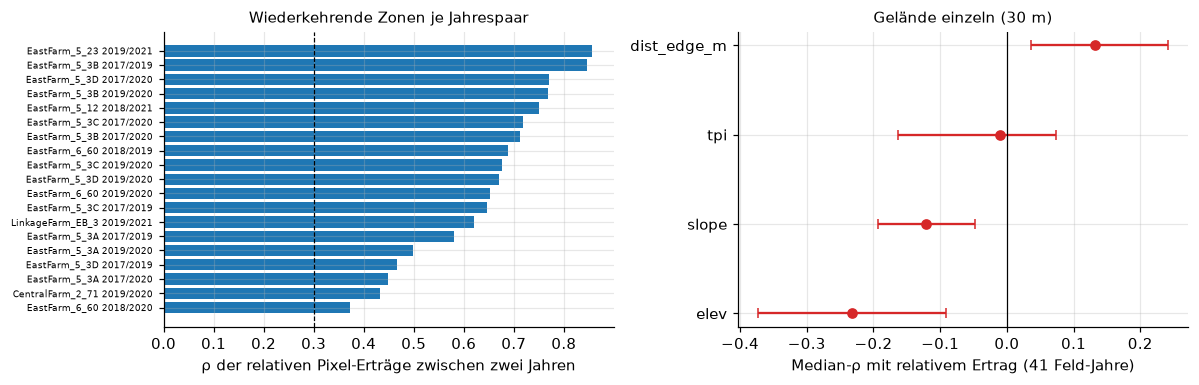

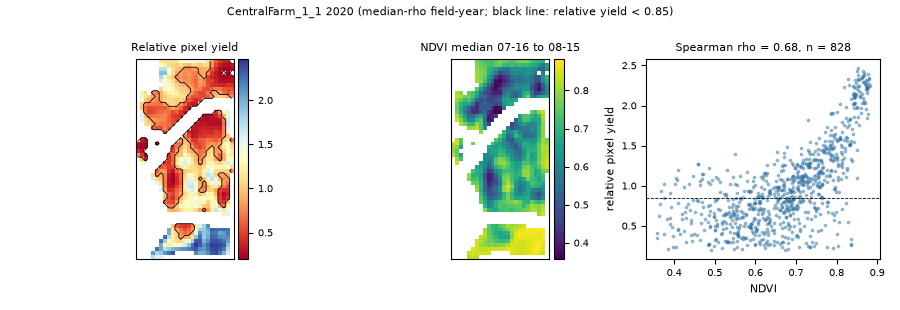

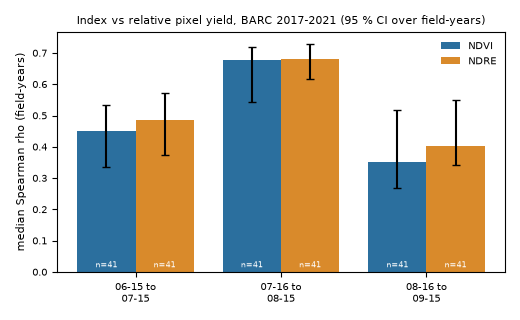

In [10]:
rec = wf["recurring"]
print(f"Wiederkehrende Zonen: {rec['n_pairs']} Jahrespaare, {rec['n_fields']} Felder")
print(f"  ρ zwischen Jahren, Median {rec['pair_rho_median']:.2f} "
      f"[{rec['pair_rho_ci_field_cluster'][0]:.2f}; {rec['pair_rho_ci_field_cluster'][1]:.2f}] "
      f"(Spanne {rec['pair_rho_min']:.2f}–{rec['pair_rho_max']:.2f}, alle > 0,3: {rec['frac_pair_rho_gt_0_3'] == 1})")
print(f"  Mittel der anderen Jahre sagt ausgelassenes Jahr voraus: ρ {rec['loyo_site_mean_rho_median']:.2f} "
      f"[{rec['loyo_site_mean_rho_ci_field_cluster'][0]:.2f}; {rec['loyo_site_mean_rho_ci_field_cluster'][1]:.2f}] "
      f"(n = {rec['loyo_site_mean_n_fy']} Feld-Jahre)")
mr = rec["model_rho_on_same_field_years"]
print(f"  Auf denselben Feld-Jahren (ganzes Feld aus, LightGBM): Satellit {mr['satellite|lgbm|lofo']:.2f}, "
      f"Gelände {mr['terrain|lgbm|lofo']:.2f}")

pairs = pd.read_csv(WF / "recurring_pairs.csv").sort_values("rho").reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].barh(range(len(pairs)), pairs.rho, color="#1f77b4")
axes[0].set_yticks(range(len(pairs)), pairs.field_id + " " + pairs.year_a.astype(str) + "/" + pairs.year_b.astype(str), fontsize=6)
axes[0].axvline(0.3, color="k", lw=0.8, ls="--")
axes[0].set_xlabel("ρ der relativen Pixel-Erträge zwischen zwei Jahren")
axes[0].set_title("Wiederkehrende Zonen je Jahrespaar", fontsize=10)
terr = pd.DataFrame([{"Merkmal": k, "ρ": v["rho_median"], "lo": v["rho_ci"][0], "hi": v["rho_ci"][1]}
                     for k, v in wf["terrain_vs_rel_yield"].items()])
axes[1].errorbar(terr["ρ"], range(len(terr)), xerr=[terr["ρ"] - terr["lo"], terr["hi"] - terr["ρ"]], fmt="o", capsize=3, color="#d62728")
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set_yticks(range(len(terr)), terr["Merkmal"])
axes[1].set_xlabel("Median-ρ mit relativem Ertrag (41 Feld-Jahre)")
axes[1].set_title("Gelände einzeln (30 m)", fontsize=10)
plt.tight_layout()
plt.show()

for f in ["phase2_within_field_maps.png", "phase2_within_field_rho.png"]:
    display(Image(FIG / f, width=700))

**Lesart:** Im Mittel der Feld-Jahre ordnet der S2-Index Mitte Juli bis Mitte August die Ertragszonen mit Median-ρ ≈ 0,68 (früher und später schwächer).
Schwache Zonen liegen meist jedes Jahr am selben Ort (ρ zwischen Jahren ≈ 0,67). Das 30-m-Gelände erklärt davon wenig. Das Pixelmodell mit Gelände zusätzlich zum Satelliten ändert kaum etwas.
Einschränkung: ein Standort, 41 Feld-Jahre, S2-Bänder B8A/B5 nativ 20 m (Pixelaussagen unter ca. 20 m nicht belastbar), äußerer Feldrand fehlt (−10-m-Puffer).

## 7. Kurze Antwort auf F0 und F1

*(sinngemäß aus `reports/data_review/phase2_models.md` übernommen; nichts Neues behauptet)*

**F0 – Wie gut sagen Satellit, Wetter und Boden den gemessenen Feldertrag voraus, und ab wann?**
Mit den verfügbaren US-Daten **nicht verlässlich für ungesehene Jahre**. Innerhalb eines Jahres ordnen Satellitenmodelle die Felder teilweise richtig (Median-ρ bis 0,40 auf S2), und für bekannte Jahre übertragen sie auf neue Felder (LOFO 0,65).
Der Jahreseffekt – der den größten Teil der RY-Streuung ausmacht – lässt sich aus 8–11 Standort-Jahren nicht lernen. Ein früher Stichtag hilft nicht; die Frühwarnkurve bleibt um 0. Kein Modell schlägt die Baseline „normales Jahr“ (B0) im RMSE.

**F1 – Welche Faktoren bestimmen den Ertrag?**
Deskriptiv hängt RY mit der späten Kurve zusammen (EVI-Integral K4, ρ = 0,44). In den Modellen verteilen sich die SHAP-Beiträge auf Satellit (0,22), Boden (0,14) und Wetter (0,13); die wichtigsten Einzelmerkmale sind aber Standort-Kennungen (Adversarial AUC 1,0), keine Ursachen.
**Innerhalb der Felder** (BARC) ist das Signal stark: S2-NDVI Mitte Juli bis Mitte August ordnet die Ertragszonen mit Median-ρ = 0,68, Problemzonen PR-AUC 0,66 bei Prävalenz 0,28; schwache Zonen liegen meist jedes Jahr am selben Ort, Gelände erklärt davon wenig.
**Fazit:** Zwischen Feldern und innerhalb eines Feldes sieht der Satellit den Ertrag gut; den Unterschied zwischen Jahren können die Modelle mit 8–11 Standort-Jahren nicht verallgemeinern. Das Kriterium „stark genug“ ist in Phase 2 und in allen drei Runden nicht erfüllt.